# Exploratory Data Analysis (EDA): Breast Cancer Wisconsin Diagnostic Dataset

**Course:** Introduction to Data Science  
**Analysis type:** Exploratory Data Analysis (EDA)  
**Dataset source:** UCI Machine Learning Repository — Breast Cancer Wisconsin (Diagnostic)  
**Public source link:** https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic  
**Notebook approach:** The dataset is loaded from scikit-learn's bundled copy of the Wisconsin Diagnostic dataset. This makes the notebook reproducible in Colab/Jupyter without manually downloading a CSV.

## 1. Dataset introduction

The dataset contains measurements computed from digitized images of fine-needle aspirate (FNA) samples of breast masses. The target indicates whether a sample is **malignant** or **benign**. The goal of this EDA is to understand feature distributions, target balance, relationships between measurements, and possible unusual observations before any predictive modeling.

> **Important:** This is an educational data-analysis exercise, not a medical diagnostic tool. Findings describe patterns in this dataset and should not be used for clinical decisions.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)

# Load the public Wisconsin Diagnostic dataset bundled with scikit-learn
dataset = load_breast_cancer(as_frame=True)
df = dataset.frame.copy()

# scikit-learn encodes 0 = malignant and 1 = benign.
# Create readable labels for analysis.
df["diagnosis"] = df["target"].map({0: "malignant", 1: "benign"})
df = df.drop(columns=["target"])

print("Dataset loaded successfully.")
print(f"Rows: {df.shape[0]}")
print(f"Columns (including diagnosis): {df.shape[1]}")
display(df.head())


Dataset loaded successfully.
Rows: 569
Columns (including diagnosis): 31


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


### Dataset overview

- **Rows:** 569 samples.
- **Columns:** 31 columns in the analysis table: 30 numerical measurements and one diagnosis label.
- **Main features:** Measurements such as radius, texture, perimeter, area, smoothness, compactness, concavity, symmetry, and fractal dimension. Many measurements have mean, standard-error, and worst-value versions.
- **Target variable:** `diagnosis` (`malignant` or `benign`).
- **Question:** Which measurements show different distributions for malignant and benign samples, and which numerical features are most strongly related to one another and to diagnosis?


In [2]:
print("Shape:", df.shape)
print("\\nData types:")
display(df.dtypes.value_counts().rename_axis("data type").to_frame("number of columns"))
print("\\nMissing values (top 10):")
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("missing values"))
print("\\nSummary statistics:")
display(df.describe().T.round(3))


Shape: (569, 31)
\nData types:


,number of columns
data type,
float64,30
object,1


\nMissing values (top 10):


,missing values
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


\nSummary statistics:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


**Interpretation:** The table gives the dataset size, data types, missing-value counts, and numerical ranges. The measurement columns are numeric, while diagnosis is categorical. In this bundled dataset, missing values are not expected; the next cell checks this explicitly. Features are measured on different scales, so scaling would be needed before some distance-based or regularized models.

## 2. Univariate EDA — individual feature distributions

Histograms show the shape and spread of numerical variables. Density curves provide a smoothed view of the same distribution. Boxplots summarize the median, quartiles, spread, and potential outliers. We focus on a representative set of features to keep the notebook readable.

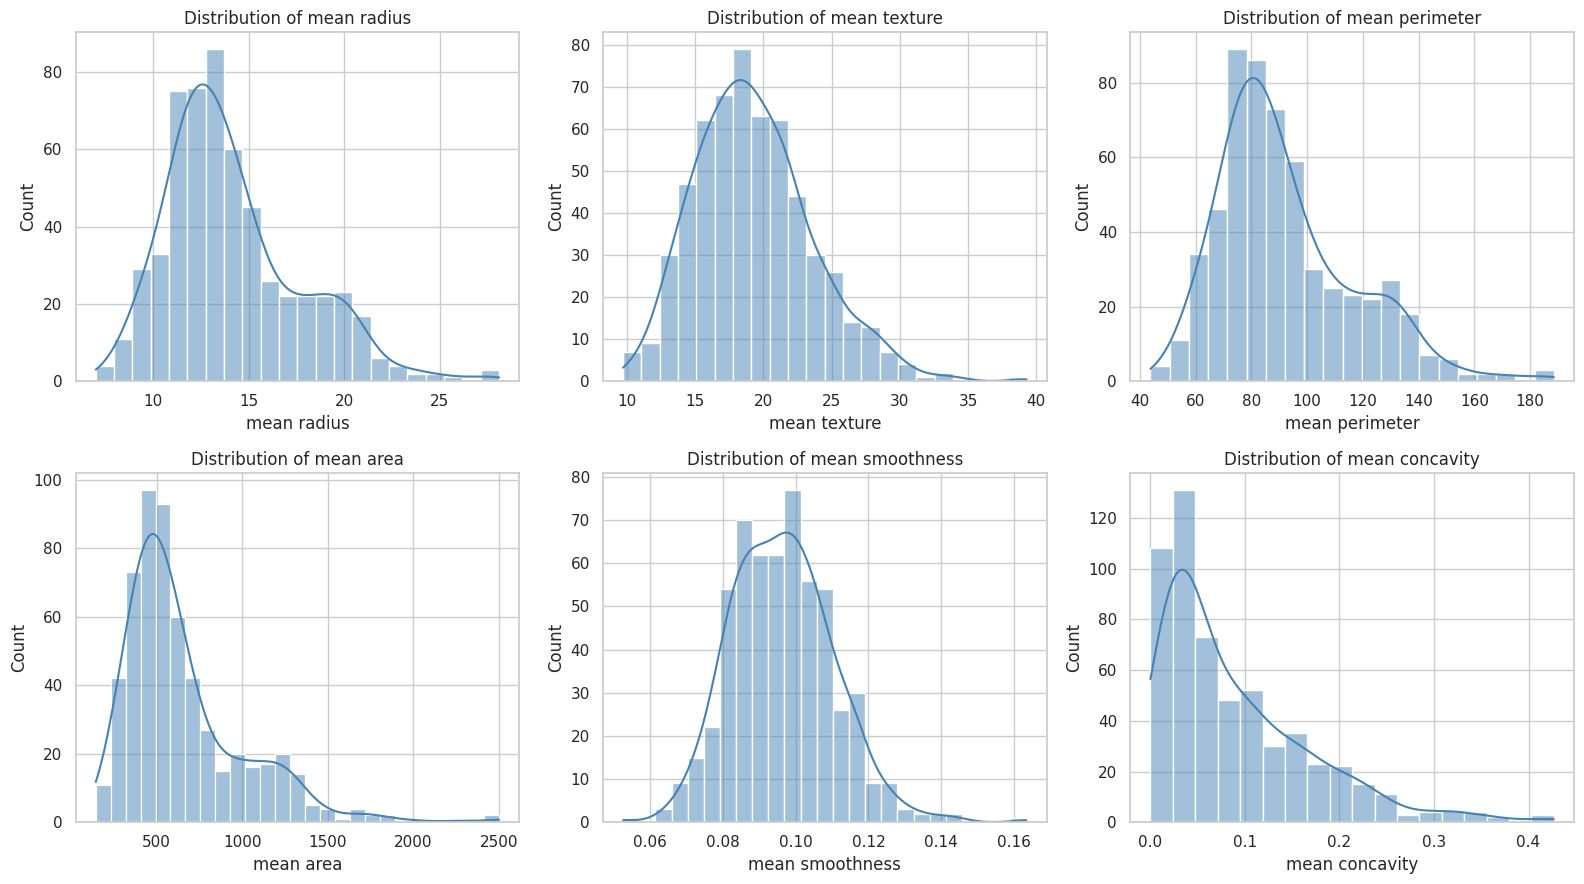

In [3]:
selected_features = [
    "mean radius", "mean texture", "mean perimeter",
    "mean area", "mean smoothness", "mean concavity"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, feature in zip(axes.flat, selected_features):
    sns.histplot(data=df, x=feature, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Distribution of {feature}")
plt.tight_layout()
plt.show()


**Interpretation:** The histograms and density curves reveal whether measurements are symmetric or skewed and whether values cluster in particular ranges. Size-related measurements such as radius, perimeter, and area often have right-skewed distributions, with a smaller number of samples having much larger values. Smoothness and texture are on different scales from size measurements, which is another reason to standardize features before scale-sensitive modeling.

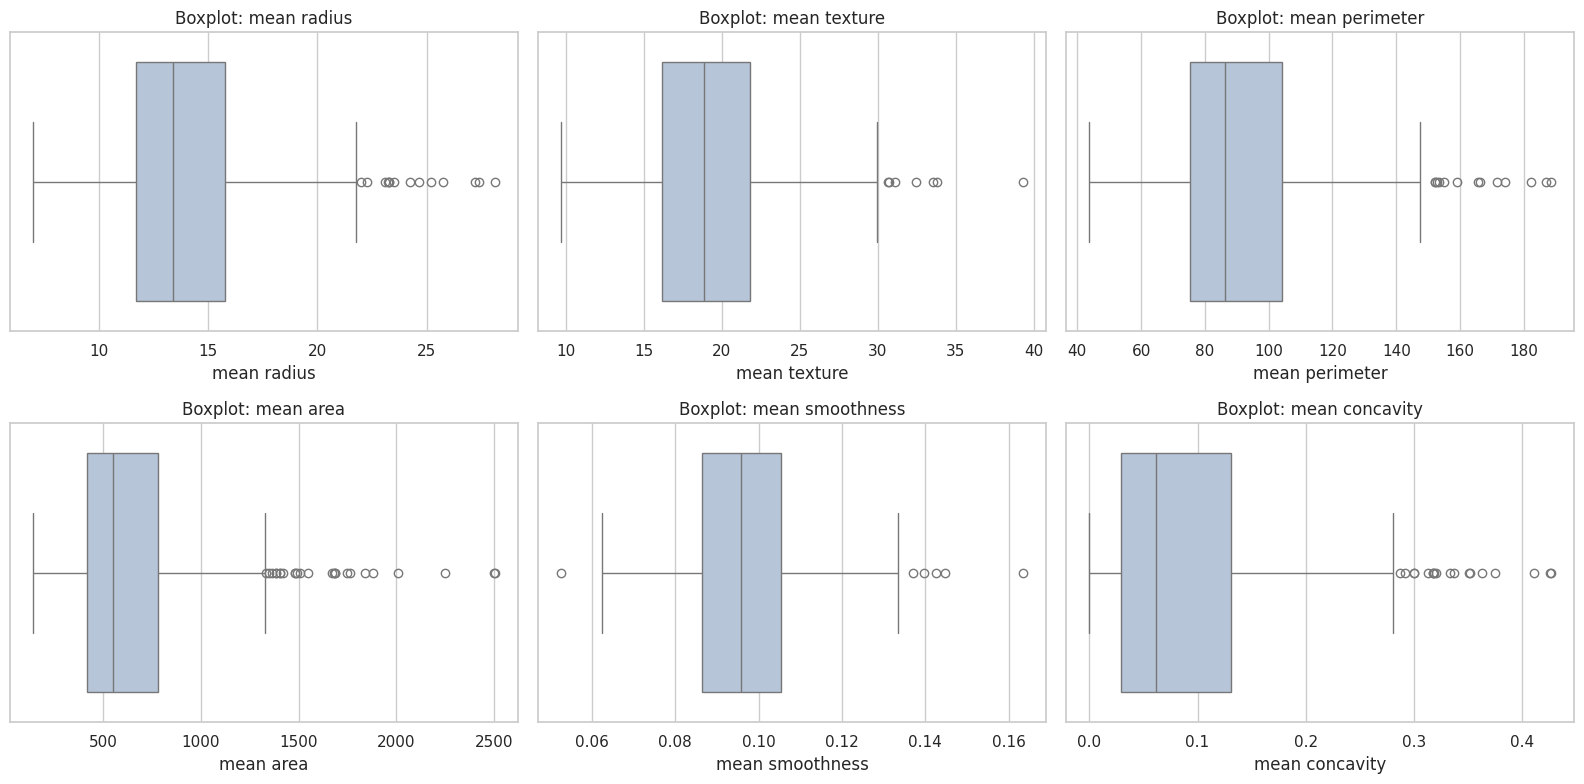

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, feature in zip(axes.flat, selected_features):
    sns.boxplot(data=df, x=feature, ax=ax, color="lightsteelblue")
    ax.set_title(f"Boxplot: {feature}")
plt.tight_layout()
plt.show()


**Interpretation:** The boxplots make medians, interquartile ranges, and points beyond the whiskers easier to compare. Some high-end values may be flagged as potential outliers. An outlier is not automatically an error: it may be a genuine sample with unusually large measurements, so it should be investigated rather than removed automatically.

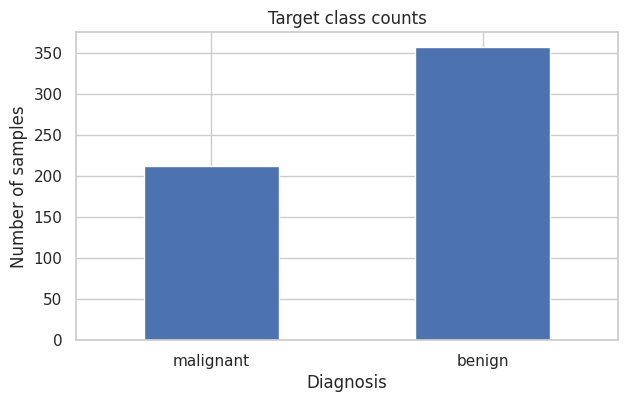

,count,percentage
diagnosis,,
malignant,212,37.26
benign,357,62.74


In [5]:
target_counts = df["diagnosis"].value_counts().reindex(["malignant", "benign"])
plt.figure(figsize=(7, 4))
target_counts.plot(kind="bar")
plt.title("Target class counts")
plt.xlabel("Diagnosis")
plt.ylabel("Number of samples")
plt.xticks(rotation=0)
plt.show()

target_pct = (df["diagnosis"].value_counts(normalize=True) * 100).reindex(["malignant", "benign"]).round(2)
display(pd.DataFrame({"count": target_counts, "percentage": target_pct}))

## 3. Target analysis

**Interpretation:** The target contains two classes, malignant and benign. The count chart and percentage table show the class distribution. The classes are not perfectly balanced; benign samples are more common than malignant samples. This is a moderate class imbalance, so future model evaluation should include precision, recall, F1-score, and a confusion matrix rather than relying on accuracy alone.

## 4. Bivariate EDA — relationships between two variables

We compare selected measurements across diagnosis groups and examine relationships between pairs of numerical features.

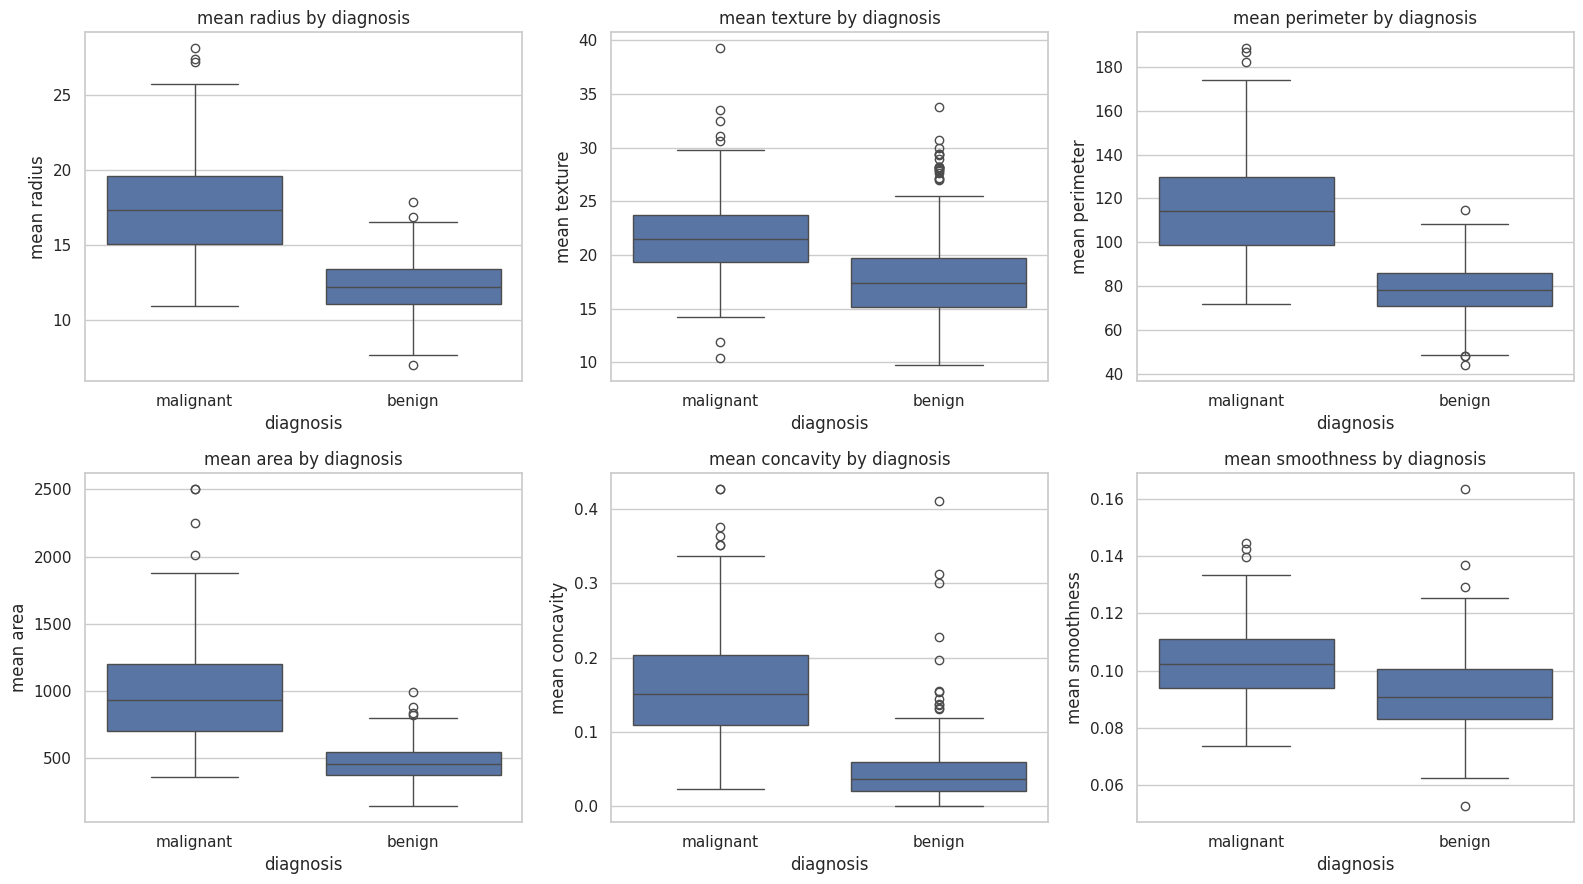

In [6]:
comparison_features = ["mean radius", "mean texture", "mean perimeter", "mean area", "mean concavity", "mean smoothness"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, feature in zip(axes.flat, comparison_features):
    sns.boxplot(data=df, x="diagnosis", y=feature, order=["malignant", "benign"], ax=ax)
    ax.set_title(f"{feature} by diagnosis")
plt.tight_layout()
plt.show()


**Interpretation:** These grouped boxplots show whether a feature's typical value differs between the two target classes. Size-related variables such as mean radius, perimeter, and area generally tend to be higher for malignant samples in this dataset, although the distributions overlap. Overlap means no single measurement perfectly separates the classes; combinations of features may be more informative.

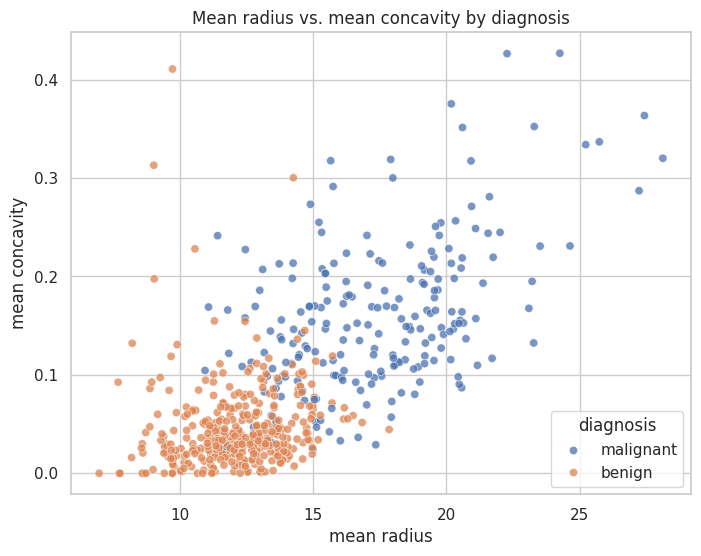

In [7]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df, x="mean radius", y="mean concavity",
    hue="diagnosis", hue_order=["malignant", "benign"],
    alpha=0.75
)
plt.title("Mean radius vs. mean concavity by diagnosis")
plt.show()


**Interpretation:** The scatter plot combines two measurements and colors each sample by diagnosis. It helps reveal clusters, overlap, and whether larger-radius samples also tend to have greater concavity. A visible group pattern can be useful for feature selection, but overlap indicates that additional measurements may be needed for reliable classification.

## 5. Correlation analysis

Pearson correlation measures the strength and direction of linear relationships between numerical features. Values close to +1 indicate strong positive relationships, values near -1 indicate strong negative relationships, and values near 0 indicate weak linear relationships. Correlation does not establish causation.

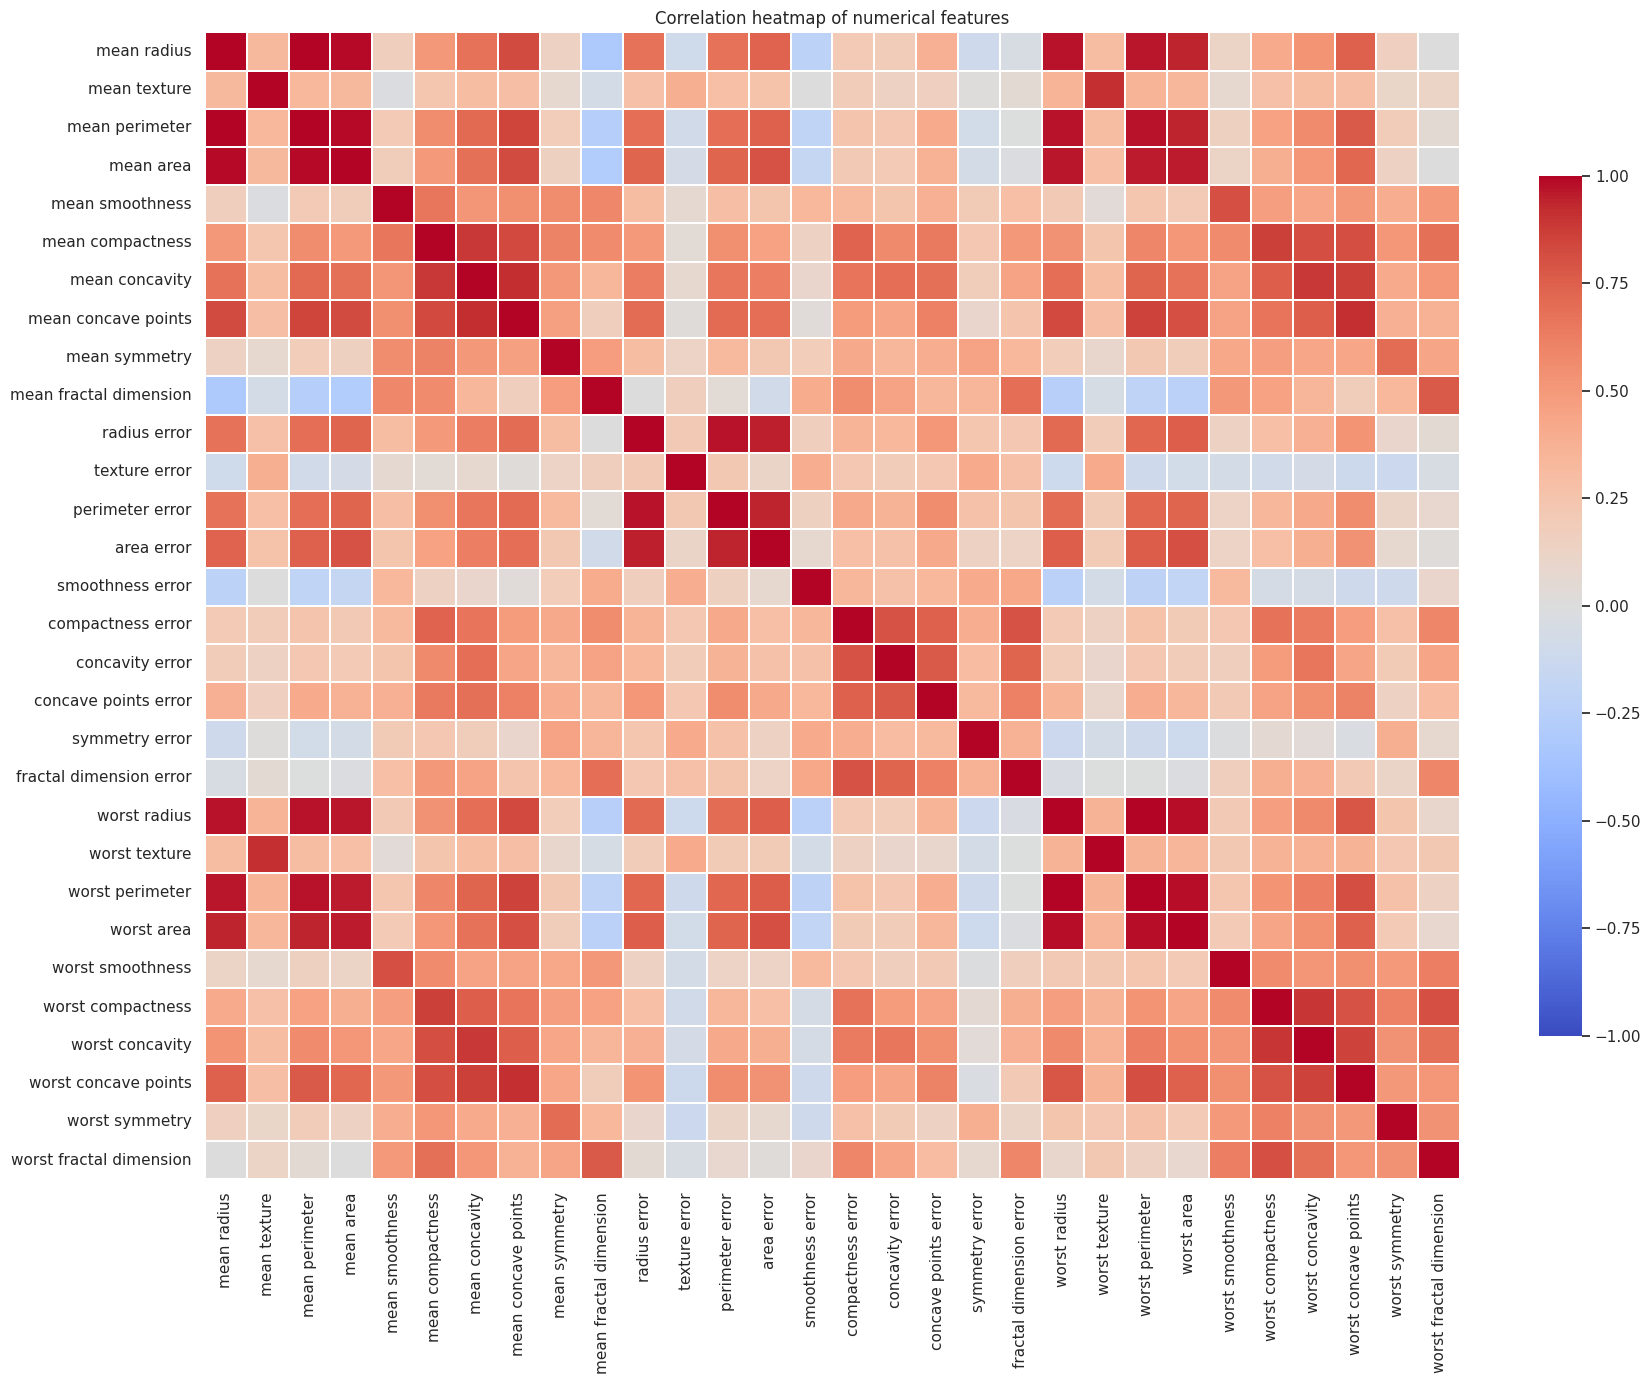

,,Pearson correlation
mean radius,mean perimeter,0.998
worst radius,worst perimeter,0.994
mean radius,mean area,0.987
mean perimeter,mean area,0.987
worst radius,worst area,0.984
worst perimeter,worst area,0.978
radius error,perimeter error,0.973
mean perimeter,worst perimeter,0.970
mean radius,worst radius,0.970
mean perimeter,worst radius,0.969


In [8]:
numeric_df = df.select_dtypes(include=np.number)
corr = numeric_df.corr()

plt.figure(figsize=(18, 14))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=False,
            linewidths=0.15, cbar_kws={"shrink": 0.75})
plt.title("Correlation heatmap of numerical features")
plt.tight_layout()
plt.show()

# List the strongest absolute correlations, excluding self-correlations
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
strong_pairs = upper.stack().sort_values(key=lambda s: s.abs(), ascending=False)
display(strong_pairs.head(15).rename("Pearson correlation").to_frame().round(3))


**Interpretation:** The heatmap typically shows strong positive correlations among related size measurements, for example radius, perimeter, and area. This is expected because these variables describe related aspects of the same mass. Some feature pairs are only weakly correlated, suggesting they capture different properties. Strongly correlated predictors can create multicollinearity in some models, so future modeling could compare a regularized model with a feature-reduced approach.

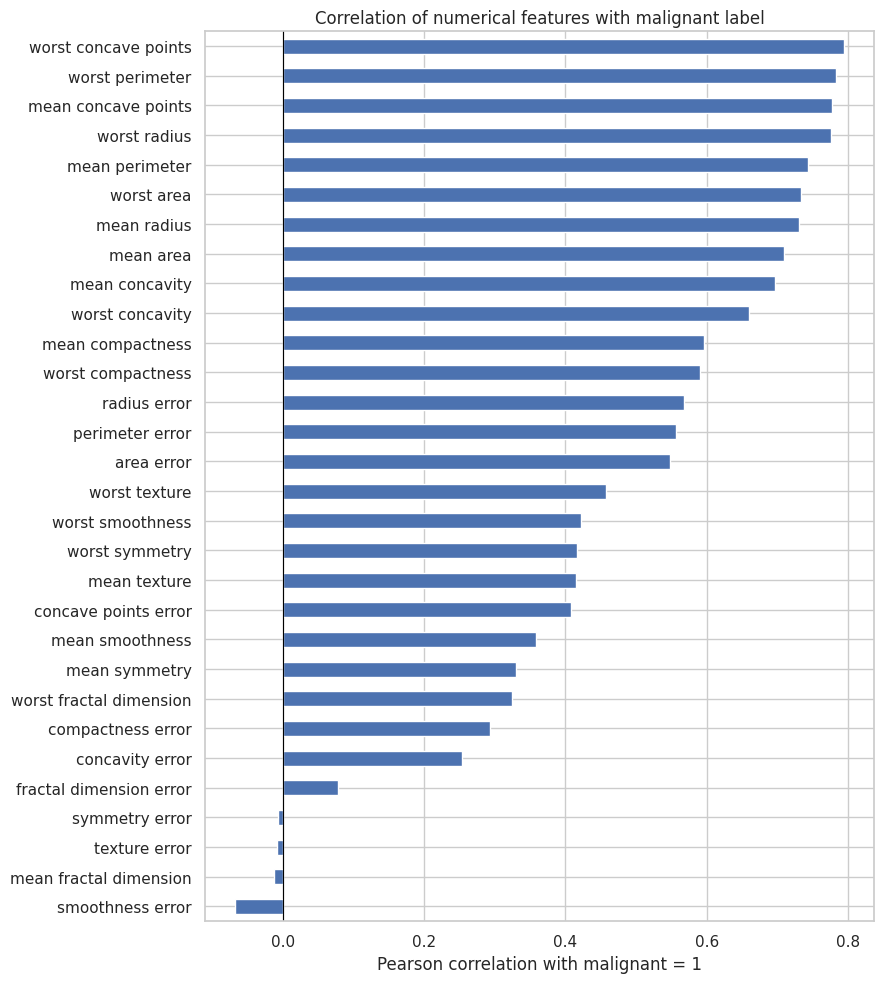

,correlation
worst concave points,0.794
worst perimeter,0.783
mean concave points,0.777
worst radius,0.776
mean perimeter,0.743
worst area,0.734
mean radius,0.730
mean area,0.709
mean concavity,0.696
worst concavity,0.660


In [9]:
# Correlation of numeric measurements with a binary target encoding.
# Here, malignant = 1 and benign = 0, making the direction easier to interpret.
target_binary = (df["diagnosis"] == "malignant").astype(int)
target_corr = numeric_df.corrwith(target_binary).dropna().sort_values()

plt.figure(figsize=(9, 10))
target_corr.plot(kind="barh")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation of numerical features with malignant label")
plt.xlabel("Pearson correlation with malignant = 1")
plt.tight_layout()
plt.show()

display(target_corr.sort_values(key=lambda s: s.abs(), ascending=False).head(10).rename("correlation").to_frame().round(3))


**Interpretation:** Positive correlations indicate that higher feature values tend to occur more often in malignant samples under this encoding; negative correlations indicate the reverse. These are associations, not causal effects. Because the target is binary, the correlations are a compact way to screen features, but they should not replace class-wise plots or proper model validation.

## 6. Multivariate EDA — several features together

Principal Component Analysis (PCA) compresses correlated numerical features into a smaller number of combined dimensions. It is used here only for visualization, not as a predictive model. Standardization is applied first because features use different units and scales.

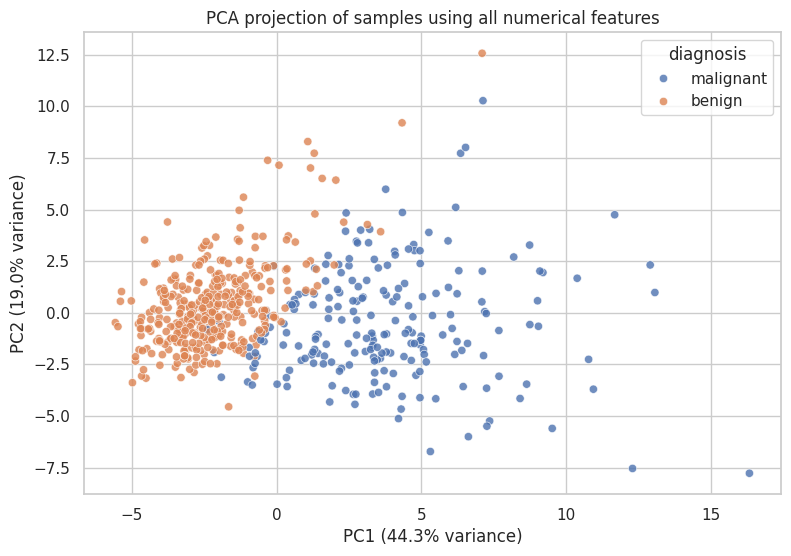

Variance explained by first two components: 63.24%


In [10]:
X = numeric_df.copy()
X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2, random_state=42)
components = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1": components[:, 0],
    "PC2": components[:, 1],
    "diagnosis": df["diagnosis"].values
})

plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="diagnosis",
                hue_order=["malignant", "benign"], alpha=0.8)
plt.title("PCA projection of samples using all numerical features")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.show()

print("Variance explained by first two components:",
      f"{pca.explained_variance_ratio_.sum()*100:.2f}%")


**Interpretation:** Each point represents one sample after combining all standardized measurements into two principal components. If the two diagnosis groups form partly separate regions, the measurements jointly contain information related to diagnosis. Any overlap shows that two dimensions do not perfectly separate all samples. PCA is a visualization aid; its apparent separation does not prove that a model will generalize to new data.

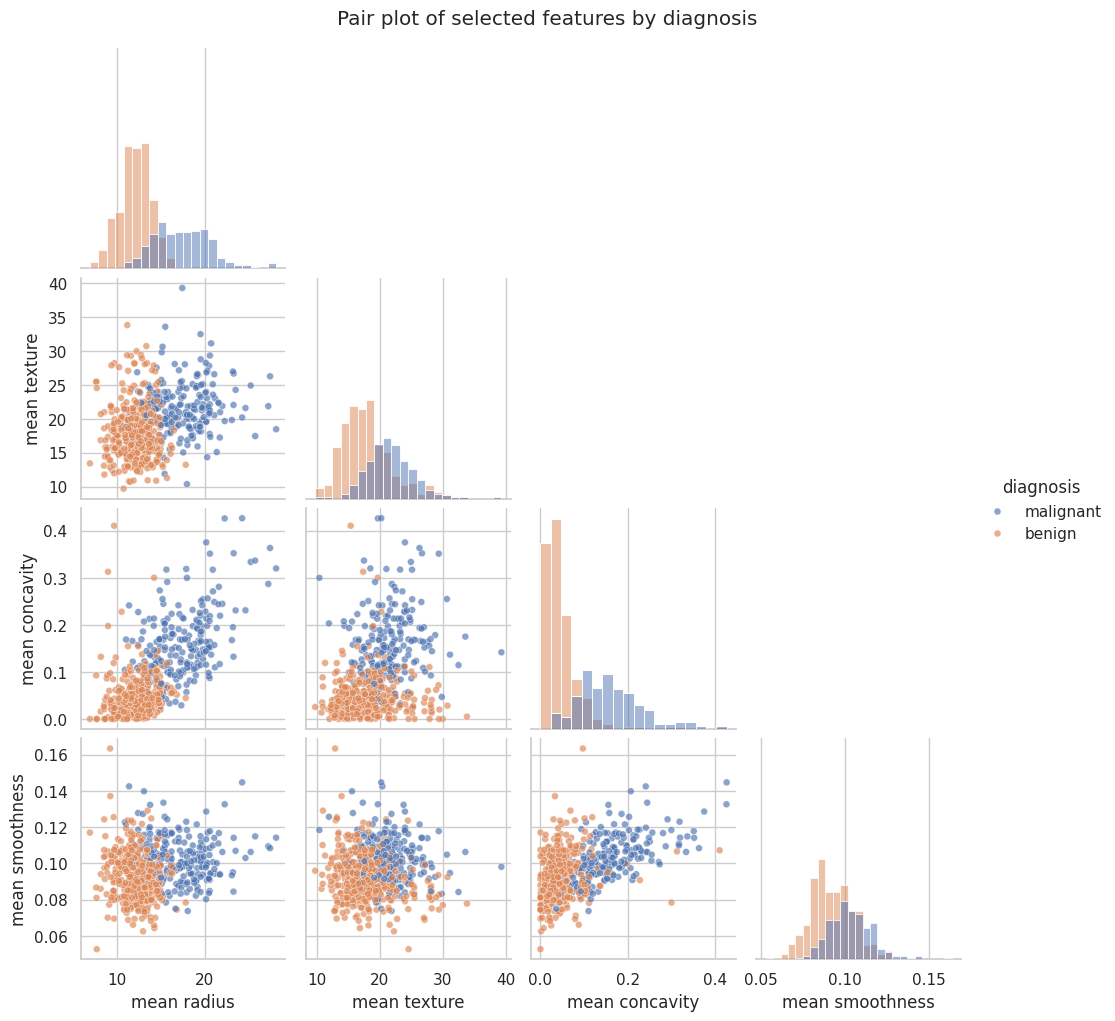

In [11]:
# Compare a few features jointly using a compact pair plot
pair_features = ["mean radius", "mean texture", "mean concavity", "mean smoothness", "diagnosis"]
sns.pairplot(
    df[pair_features],
    hue="diagnosis",
    hue_order=["malignant", "benign"],
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.65, "s": 25}
)
plt.suptitle("Pair plot of selected features by diagnosis", y=1.02)
plt.show()


**Interpretation:** The pair plot lets us inspect several pairwise relationships at once. It can show whether individual variables or pairs of variables create clearer class separation, and whether the relationships are linear or more complex. This supports the idea that multivariate combinations may be more useful than a single feature.

## 7. Patterns, trends, and unusual observations

The following checks identify potential outliers using the standard 1.5 × IQR rule. This is a flagging method, not proof that a record is wrong. We also inspect duplicate rows and missing values.

In [12]:
# Missing and duplicate checks
print("Total missing cells:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

# Count IQR-rule outliers in selected features
outlier_rows = []
for feature in selected_features:
    q1 = df[feature].quantile(0.25)
    q3 = df[feature].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    count = int(((df[feature] < lower) | (df[feature] > upper_bound)).sum())
    outlier_rows.append({
        "feature": feature,
        "lower fence": lower,
        "upper fence": upper_bound,
        "potential outliers": count
    })

display(pd.DataFrame(outlier_rows).set_index("feature").round(3))


Total missing cells: 0
Duplicate rows: 0


,lower fence,upper fence,potential outliers
feature,,,
mean radius,5.580,21.900,14
mean texture,7.725,30.245,7
mean perimeter,31.775,147.495,13
mean area,-123.300,1326.300,25
mean smoothness,0.058,0.134,6
mean concavity,-0.122,0.282,18


**Interpretation:** The missing-value and duplicate checks help assess basic data quality. IQR-based flags highlight samples far from the middle 50% of each feature. These may represent valid extreme cases, especially in biological measurements. For a future model, extreme values should be reviewed and the impact of robust scaling or outlier-sensitive methods considered rather than deleting observations without justification.

## 8. Final findings (key insights)

1. **The dataset has 569 samples and 30 numerical predictors**, plus a binary diagnosis label. It is small enough for detailed visualization and baseline modeling.
2. **The target has two classes and is moderately imbalanced**, with benign samples more frequent. Future evaluation should include class-sensitive metrics such as recall, precision, F1-score, and the confusion matrix.
3. **Size-related features are strongly related.** Radius, perimeter, and area measure connected aspects of mass size and tend to show strong positive correlations.
4. **Several size and shape measurements differ between diagnosis groups.** In particular, malignant samples tend to have larger values for some radius-, perimeter-, area-, and concavity-related measurements, although the classes overlap.
5. **No single feature perfectly separates the target classes.** Bivariate and multivariate views show why combining measurements may be useful.
6. **Potential outliers occur in some numerical features.** They should be investigated as potentially meaningful extreme samples, not automatically removed.
7. **Features have different numerical scales.** Standardization is appropriate before PCA and may be needed for models such as logistic regression, support vector machines, and k-nearest neighbors.
8. **Correlated predictors may create redundancy.** Feature selection, regularization, or dimensionality reduction could be tested in a later modeling stage.

### How these findings may help future modeling

These EDA results can guide a train/test split with stratification, feature scaling, class-sensitive evaluation, and experiments with regularized models or dimensionality reduction. Any model should be validated on held-out data, and no clinical conclusions should be drawn from this classroom analysis.


## 9. References

- UCI Machine Learning Repository. *Breast Cancer Wisconsin (Diagnostic) Data Set.* https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
- scikit-learn documentation. *Breast cancer Wisconsin (diagnostic) dataset.* https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html

**Submission reminder:** Run all cells in Google Colab or Jupyter Notebook, review the generated plots and outputs, then upload the `.ipynb` file to a public GitHub repository or Zenodo record. Submit only the public link on LMS, as required by the assignment.
